In [12]:
import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
%matplotlib inline

In [2]:
df = pd.read_csv("_data.csv")

In [5]:
df.head()

,Unnamed: 0,ID объявления,Количество комнат,Тип,Метро,Адрес,"Площадь, м2",Дом,Парковка,Цена,...,Окна,Санузел,Можно с детьми/животными,Дополнительно,Название ЖК,Серия дома,"Высота потолков, м",Лифт,Мусоропровод,Ссылка на объявление
0,0,271271157,4,Квартира,м. Смоленская (9 мин пешком),"Москва, улица Новый Арбат, 27",200.0/20.0,"5/16, Монолитный",подземная,"500000.0 руб./ За месяц, Залог - 500000 руб., ...",...,NaN,NaN,"Можно с детьми, Можно с животными","Мебель в комнатах, Мебель на кухне, Ванна, Душ...","Новый Арбат, 2010",NaN,3.0,"Пасс (4), Груз (1)",Да,https://www.cian.ru/rent/flat/271271157
1,1,271634126,4,Квартира,м. Смоленская (8 мин пешком),"Москва, улица Новый Арбат, 27",198.0/95.0/18.0,"5/16, Монолитно-кирпичный",подземная,"500000.0 руб./ За месяц, Залог - 500000 руб., ...",...,На улицу и двор,"Совмещенный (2), Раздельный (1)",Можно с детьми,"Мебель в комнатах, Мебель на кухне, Ванна, Душ...",Новый Арбат,NaN,3.5,"Пасс (1), Груз (1)",Нет,https://www.cian.ru/rent/flat/271634126
2,2,271173086,"4, Оба варианта",Квартира,м. Смоленская (7 мин пешком),"Москва, улица Новый Арбат, 27",200.0/116.0/4.0,5/16,подземная,"500000.0 руб./ За месяц, Залог - 500000 руб., ...",...,На улицу и двор,Совмещенный (3),Можно с детьми,"Мебель в комнатах, Мебель на кухне, Ванна, Душ...",Новый Арбат,NaN,3.2,Пасс (1),NaN,https://www.cian.ru/rent/flat/271173086
3,3,272197456,"4, Оба варианта",Квартира,м. Смоленская (3 мин пешком),"Москва, переулок Плотников, 21С1",170.0/95.0/17.0,5/6,подземная,"400000.0 руб./ За месяц, Залог - 400000 руб., ...",...,На улицу и двор,Совмещенный (3),Можно с животными,"Мебель в комнатах, Мебель на кухне, Ванна, Душ...",NaN,NaN,3.2,Пасс (1),NaN,https://www.cian.ru/rent/flat/272197456
4,4,273614615,2,Квартира,м. Арбатская (7 мин пешком),"Москва, улица Новый Арбат, 15",58.0/38.0/5.0,"12/26, Панельный",NaN,"225000.0 руб./ За месяц, Залог - 225000 руб., ...",...,На улицу и двор,Совмещенный (2),NaN,"Мебель в комнатах, Мебель на кухне, Ванна, Душ...",The Book,NaN,3.9,"Пасс (1), Груз (1)",Да,https://www.cian.ru/rent/flat/273614615


In [ ]:
print(f"Количество объявлений: {df.shape[0]:,}")
print(f"Количество столбцов: {df.shape[1]}")
display(df.head())

In [ ]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,23368.0,NaN,NaN,NaN,11683.5,6745.904881,0.0,5841.75,11683.5,17525.25,23367.0
ID объявления,23368.0,NaN,NaN,NaN,267626523.825103,18768615.252984,107298592.0,271266347.0,273903027.5,274687218.5,275006443.0
Количество комнат,22327,24,1,7917,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Тип,23368,1,Квартира,23368,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Метро,22053,5866,м. Академическая (10 мин пешком),41,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Адрес,23368,12850,"Москва, Чапаевский переулок, 3",63,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"Площадь, м2",23368,11255,40.0/20.0/10.0,224,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Дом,23368,2565,"3/5, Кирпичный",322,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Парковка,9951,5,наземная,6043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Цена,23368,3922,"40000.0 руб./ За месяц, Залог - 40000 руб., Ко...",1113,NaN,NaN,NaN,NaN,NaN,NaN,NaN


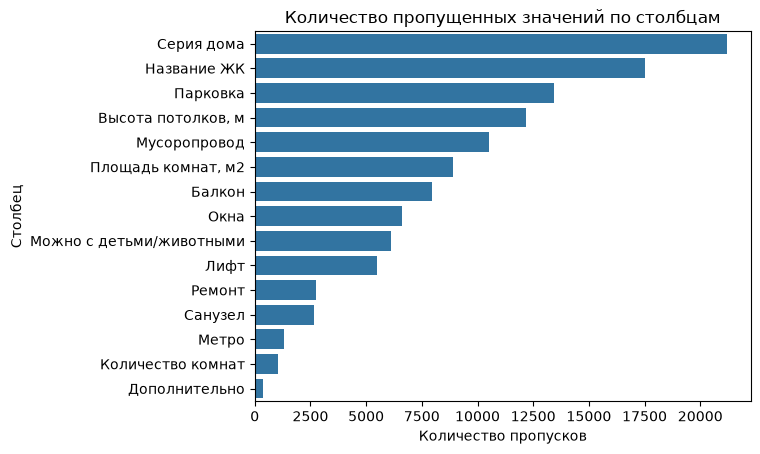

In [39]:
missing = (df.isna().sum().sort_values(ascending=False))

missing = missing[missing > 0]

sns.barplot(x=missing.values, y=missing.index)
plt.title("Количество пропущенных значений по столбцам")
plt.xlabel("Количество пропусков")
plt.ylabel("Столбец")

plt.show()

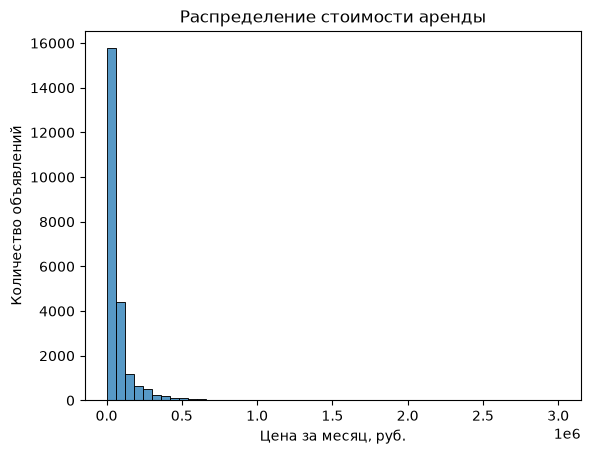

Медианная цена: 49500.0
Средняя цена: 82894.13875813078


In [ ]:
price = pd.to_numeric(
    df["Цена"].astype("string")
      .str.replace("\u00a0", "", regex=False)
      .str.extract(r"(\d+(?:[.,]\d+)?)", expand=False)
      .str.replace(",", ".", regex=False),
    errors="coerce"
)

price = price.dropna()
price = price[price > 0]


sns.histplot(price, bins=50)
plt.title("Распределение стоимости аренды")
plt.xlabel("Цена за месяц, руб.")
plt.ylabel("Количество объявлений")
plt.show()

print("Медианная цена:", price.median())
print("Средняя цена:", price.mean())

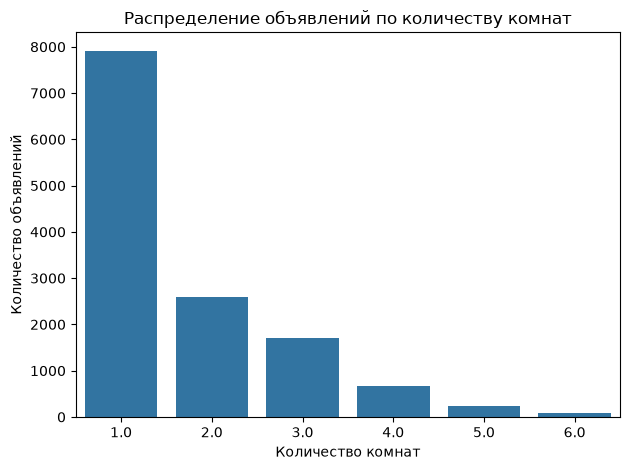

In [32]:
rooms = pd.to_numeric(df["Количество комнат"], errors="coerce")

sns.countplot(x=rooms.dropna())
plt.title("Распределение объявлений по количеству комнат")
plt.xlabel("Количество комнат")
plt.ylabel("Количество объявлений")
plt.tight_layout()
plt.show()

In [ ]:
print("Полных дубликатов:", df.duplicated().sum())

if "ID объявления" in df.columns:
    print("Повторяющихся ID:", df["ID объявления"].duplicated().sum())

Всего строк: 23368
Полных дубликатов: 0
